**Set environment**

In [1]:
suppressMessages(suppressWarnings(source("../run_config_project_sing.R")))
show_env()

You are working on        Singularity: singularity_proj_encode_fcc 
BASE DIRECTORY (FD_BASE): /net/seq/data2/projects/reddylab/Kuei 
REPO DIRECTORY (FD_REPO): /net/seq/data2/projects/reddylab/Kuei/repo 
WORK DIRECTORY (FD_WORK): /net/seq/data2/projects/reddylab/Kuei/work 
DATA DIRECTORY (FD_DATA): /net/seq/data2/projects/reddylab/Kuei/data 

You are working with      ENCODE FCC 
PATH OF PROJECT (FD_PRJ): /net/seq/data2/projects/reddylab/Kuei/repo/Proj_ENCODE_FCC 
PROJECT RESULTS (FD_RES): /net/seq/data2/projects/reddylab/Kuei/repo/Proj_ENCODE_FCC/results 
PROJECT SCRIPTS (FD_EXE): /net/seq/data2/projects/reddylab/Kuei/repo/Proj_ENCODE_FCC/scripts 
PROJECT DATA    (FD_DAT): /net/seq/data2/projects/reddylab/Kuei/repo/Proj_ENCODE_FCC/data 
PROJECT NOTE    (FD_NBK): /net/seq/data2/projects/reddylab/Kuei/repo/Proj_ENCODE_FCC/notebooks 
PROJECT DOCS    (FD_DOC): /net/seq/data2/projects/reddylab/Kuei/repo/Proj_ENCODE_FCC/docs 
PROJECT LOG     (FD_LOG): /net/seq/data2/projects/reddylab/Kuei/re

## Prepare

**Set global variable**

In [2]:
vec = c(
    "fcc_astarr_macs_input_overlap",
    "fcc_astarr_macs_input_union"
)
names(vec) = vec

VEC_TXT_FOLDER = vec
for(txt in vec){cat(txt, "\n")}

fcc_astarr_macs_input_overlap 
fcc_astarr_macs_input_union 


**View files**

In [3]:
txt_folder = VEC_TXT_FOLDER[1]
txt_fdiry  = file.path(FD_RES, "analysis_fcc_comparison", txt_folder)
txt_fname = "result.comparison.fcc_starrmpracrispr.assayvote.correlation.fcc.tsv"
txt_fglob  = file.path(txt_fdiry, txt_fname)

vec = Sys.glob(txt_fglob)
for (txt in vec) {cat(txt, "\n")}

/net/seq/data2/projects/reddylab/Kuei/repo/Proj_ENCODE_FCC/results/analysis_fcc_comparison/fcc_astarr_macs_input_overlap/result.comparison.fcc_starrmpracrispr.assayvote.correlation.fcc.tsv 


## Import data

### Import FCC correlations across assay pairs

In [4]:
### loop to import data
lst = lapply(VEC_TXT_FOLDER, function(txt_folder){
    ### set file directory
    txt_fdiry  = file.path(FD_RES, "analysis_fcc_comparison", txt_folder)
    txt_fname = "result.comparison.fcc_starrmpracrispr.assayvote.correlation.fcc.tsv"
    txt_fpath = file.path(txt_fdiry, txt_fname)

    ### read table
    dat = read_tsv(txt_fpath, show_col_types = FALSE)
    return(dat)
})

### assign and show
lst_dat_result_corr_fcc_import = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
head(dat, 3)

$fcc_astarr_macs_input_overlap
[1] 140   6

$fcc_astarr_macs_input_union
[1] 140   6



Group,Total,Assay1,Assay2,scor,size
<chr>,<dbl>,<chr>,<chr>,<dbl>,<dbl>
#Assay = 0,49587,ATAC,ASTARR,0.10932931,49586
#Assay = 0,49587,ATAC,LMPRA,0.08743807,13488
#Assay = 0,49587,ATAC,TMPRA,0.09644420,120


## Arrange table

In [5]:
### classify assay type
vec_txt_assay_type = c(
    "ATAC"                  = "ATAC",
    "ASTARR"                = "STARR/MPRA",
    "WSTARR"                = "STARR/MPRA",
    "LMPRA"                 = "STARR/MPRA",
    "TMPRA"                 = "STARR/MPRA",
    "CRISPRi-Growth"        = "CRISPR",
    "CRISPRi-HCRFF"         = "CRISPR",
    "ENCODE-rE2G Benchmark" = "CRISPR"
)

### helper function to format count
format_count <- function(n) {
    ifelse(
        n < 1000,
        paste0(" (", n, ")"),
        paste0(" (", round(n / 1000), "k)")
    )
}

### arrange the results
lst = lst_dat_result_corr_fcc_import
lst = lapply(lst, function(dat){
    ### label assay type and pair
    dat = dat %>%
        dplyr::mutate(
            Assay_Type1 = vec_txt_assay_type[Assay1],
            Assay_Type2 = vec_txt_assay_type[Assay2],
            Assay_TypePair = case_when(
                Assay_Type1 == "ATAC" & Assay_Type2 == "STARR/MPRA" ~ "ATAC x STARR/MPRA",
                Assay_Type1 == "ATAC" & Assay_Type2 == "CRISPR"     ~ "ATAC x CRISPR",
                Assay_Type1 == "STARR/MPRA" & Assay_Type2 == "STARR/MPRA" ~ "STARR/MPRA",
                Assay_Type1 == "CRISPR"     & Assay_Type2 == "CRISPR"     ~ "CRISPR",
                TRUE                                                      ~ "STARR/MPRA × CRISPR"
           )
        )
    ### label the group
    dat = dat %>% dplyr::mutate(Label = paste0(Group, format_count(Total)))
    return(dat)
})

## assign and show
lst_dat_result_corr_fcc_arrange = lst

res = lapply(lst, dim)
print(res)

dat = lst[[1]]
head(dat, 3)

$fcc_astarr_macs_input_overlap
[1] 140  10

$fcc_astarr_macs_input_union
[1] 140  10



Group,Total,Assay1,Assay2,scor,size,Assay_Type1,Assay_Type2,Assay_TypePair,Label
<chr>,<dbl>,<chr>,<chr>,<dbl>,<dbl>,<chr>,<chr>,<chr>,<chr>
#Assay = 0,49587,ATAC,ASTARR,0.10932931,49586,ATAC,STARR/MPRA,ATAC x STARR/MPRA,#Assay = 0 (50k)
#Assay = 0,49587,ATAC,LMPRA,0.08743807,13488,ATAC,STARR/MPRA,ATAC x STARR/MPRA,#Assay = 0 (50k)
#Assay = 0,49587,ATAC,TMPRA,0.09644420,120,ATAC,STARR/MPRA,ATAC x STARR/MPRA,#Assay = 0 (50k)


## Set plot style

In [6]:
### set text size
theme_text = theme(
    title        = element_text(size = 16),
    axis.title   = element_text(size = 16),
    axis.text    = element_text(size = 16),
    legend.title = element_text(size = 16),
    legend.text  = element_text(size = 16),
    strip.text.x = element_text(size = 16)
)

### Set color scale
vec_txt_color = c(
    "ATAC x STARR/MPRA"    = "grey30",
    "ATAC x CRISPR"        = "grey10",
    "STARR/MPRA"           = "#377eb8",
    "CRISPR"               = "#4daf4a",
    "STARR/MPRA × CRISPR"  = "#e41a1c"
)

## Explore: FCC correlations summary across assay vote

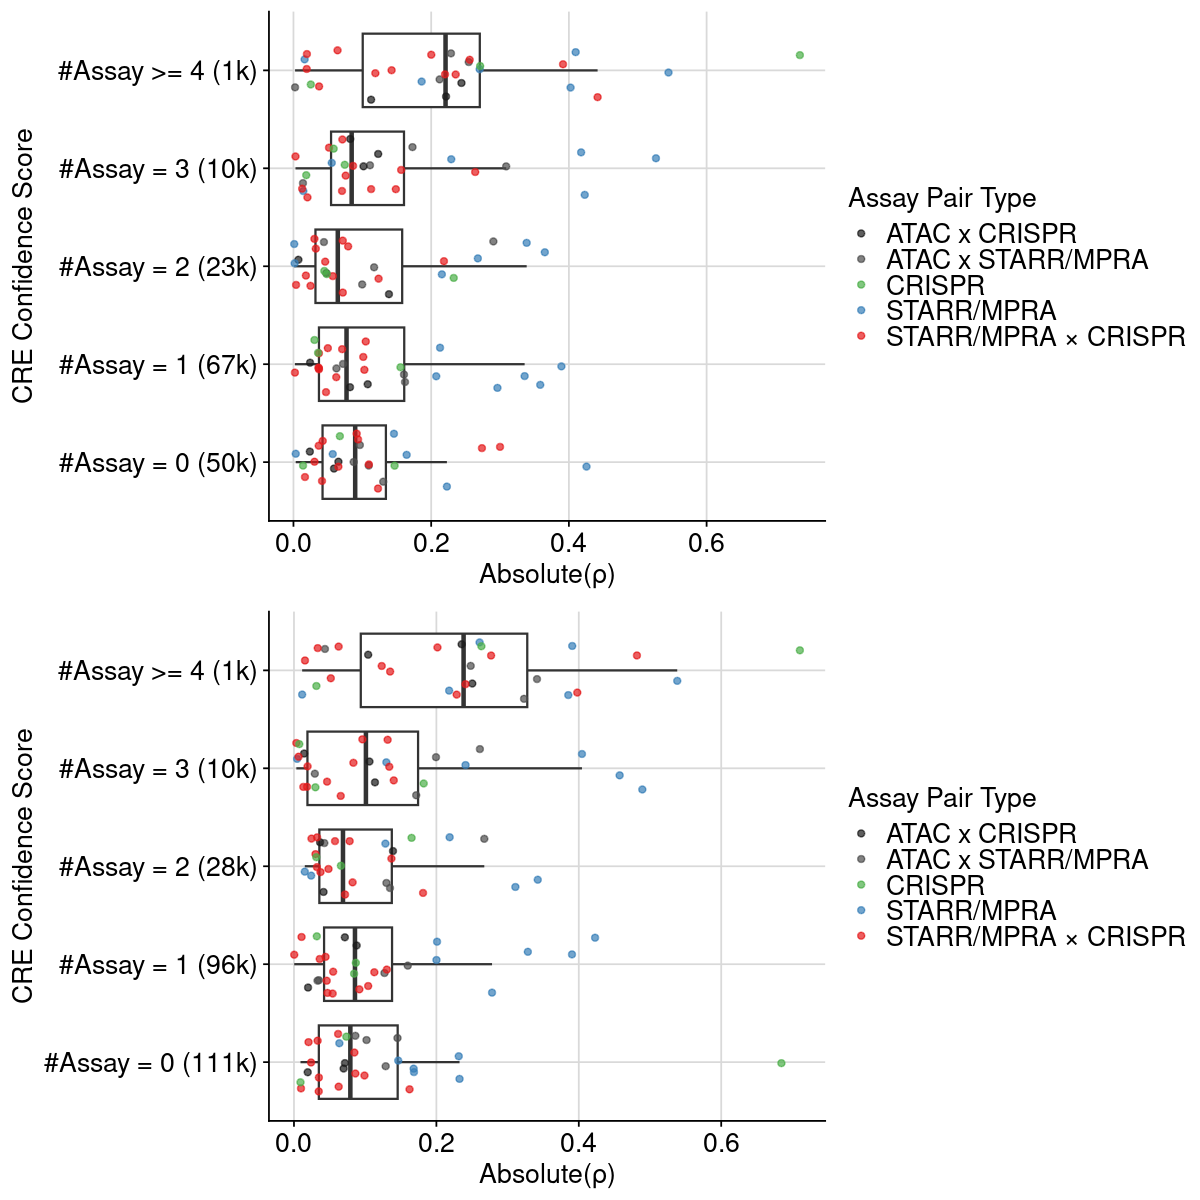

In [7]:
lst = lst_dat_result_corr_fcc_arrange
lst = lapply(lst, function(dat){
    set.seed(123)
    gpt = ggplot(dat, aes(x = Label, y = abs(scor))) +
        geom_boxplot(outlier.shape = NA) +
        geom_jitter(aes(color = Assay_TypePair), size = 1.5, width=0.3, alpha = 0.7) +
        labs(
            x = "CRE Confidence Score",
            y = "Absolute(\u03C1)",
            color = "Assay Pair Type"
        ) +
        #scale_x_discrete(labels = vec) +
        scale_color_manual(values = vec_txt_color) +
        coord_flip() +
        theme_cowplot() +
        background_grid() +
        theme_text
    return(gpt)
})

### assign and show
lst_gpt_result_corr = lst
options(repr.plot.height=10, repr.plot.width = 10)
plot_grid(plotlist = lst, ncol = 1, align = "v")

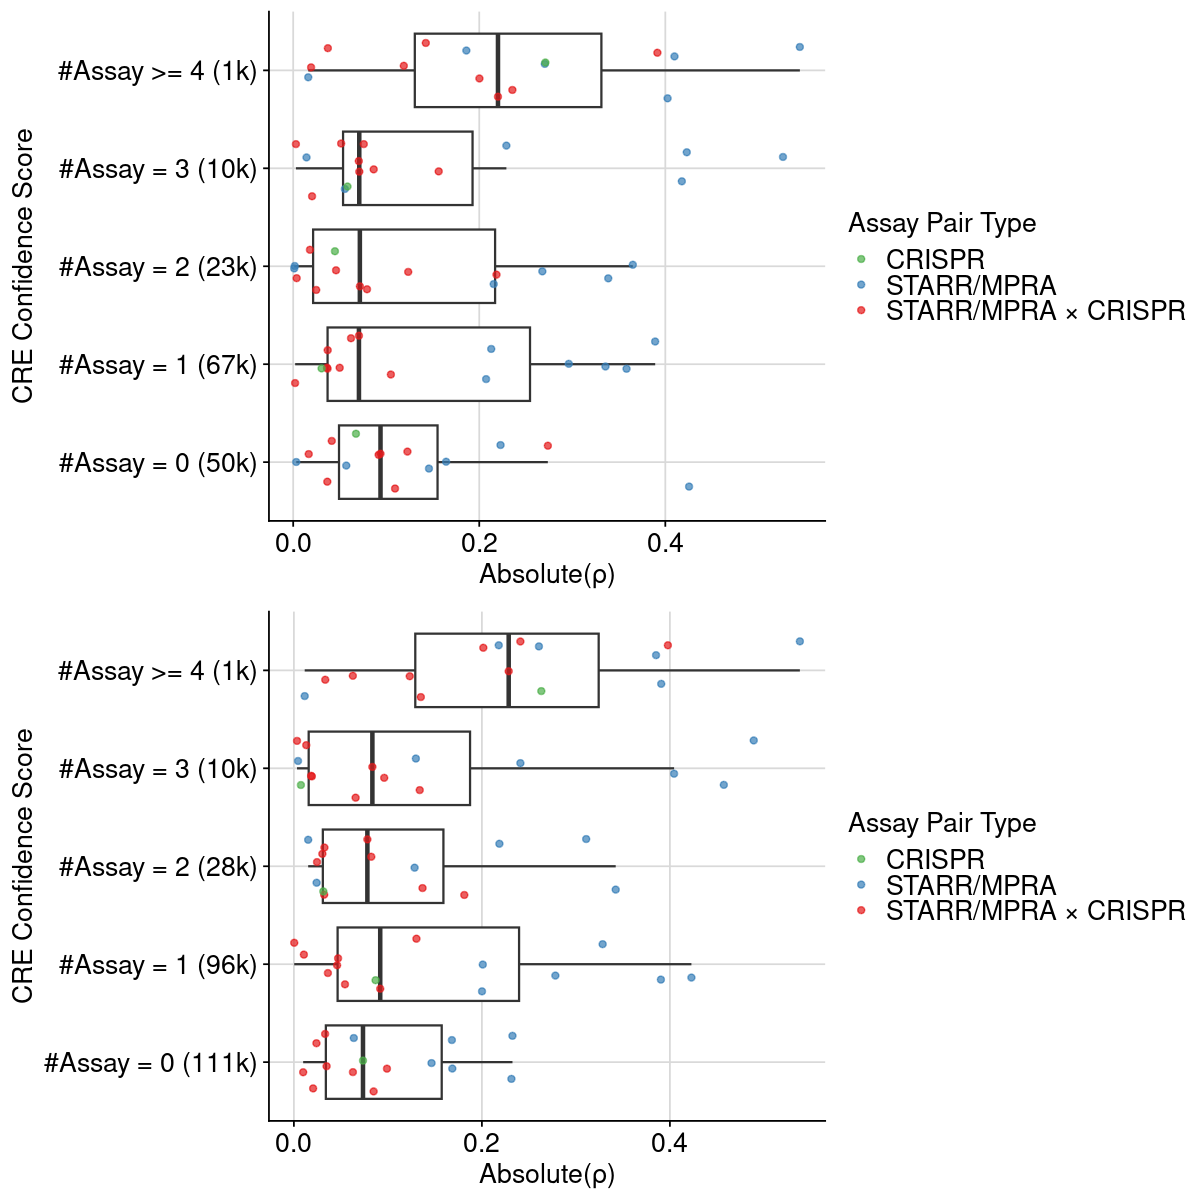

In [8]:
lst = lst_dat_result_corr_fcc_arrange
lst = lapply(lst, function(dat){
    dat = dat %>% dplyr::filter(Assay1 != "ATAC")
    dat = dat %>% dplyr::filter(Assay2 != "ENCODE-rE2G Benchmark")
    
    set.seed(123)
    gpt = ggplot(dat, aes(x = Label, y = abs(scor))) +
        geom_boxplot(outlier.shape = NA) +
        geom_jitter(aes(color = Assay_TypePair), size = 1.5, width=0.3, alpha = 0.7) +
        labs(
            x = "CRE Confidence Score",
            y = "Absolute(\u03C1)",
            color = "Assay Pair Type"
        ) +
        #scale_x_discrete(labels = vec) +
        scale_color_manual(values = vec_txt_color) +
        coord_flip() +
        theme_cowplot() +
        background_grid() +
        theme_text
    return(gpt)
})

### assign and show
lst_gpt_result_corr_rmE2G = lst
options(repr.plot.height=10, repr.plot.width = 10)
plot_grid(plotlist = lst, ncol = 1, align = "v")

## Export

In [9]:
print(VEC_TXT_FOLDER)

  fcc_astarr_macs_input_overlap     fcc_astarr_macs_input_union 
"fcc_astarr_macs_input_overlap"   "fcc_astarr_macs_input_union" 


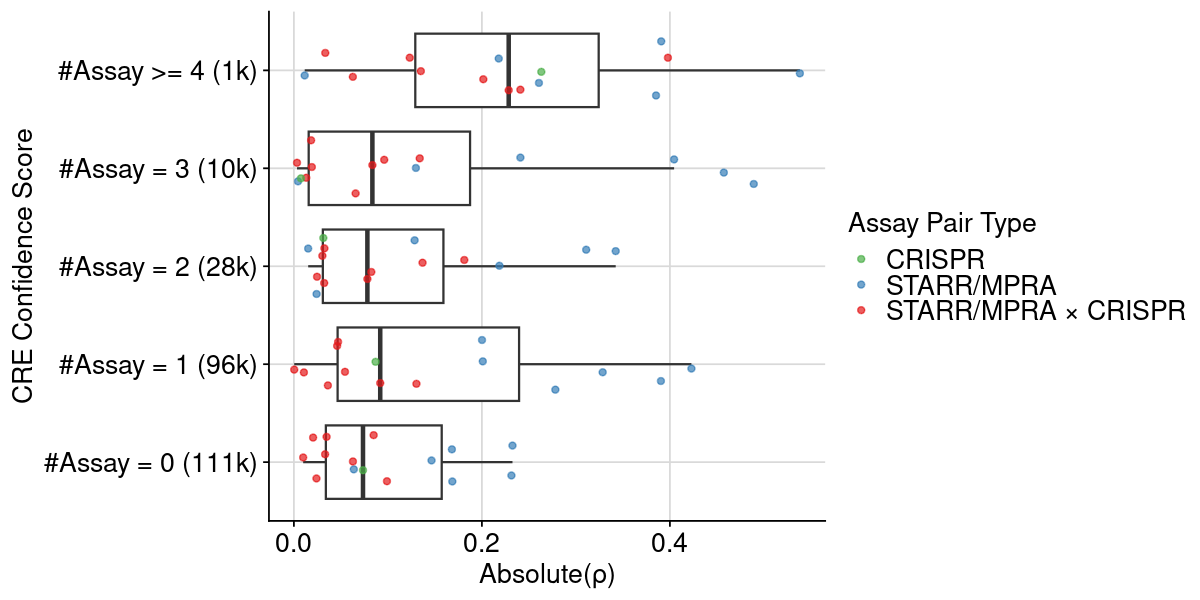

In [10]:
lst = lst_gpt_result_corr_rmE2G
idx = "fcc_astarr_macs_input_union"
gpt = lst[[idx]]

plt_export_fcc_scor = gpt
options(repr.plot.height=5, repr.plot.width = 10)
print(gpt)

**Export plots**

In [11]:
plt_export = plt_export_fcc_scor
txt_export = "fig.fcc_comparison.fcc_starrmpracrispr.assayvote.correlation.barplot"
num_height = 5
num_width  = 10

txt_fdiry = "./"
txt_fname = paste(txt_export, "png", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")

txt_fdiry = "./"
txt_fname = paste(txt_export, "svg", sep = ".")
txt_fpath = file.path(txt_fdiry, txt_fname)
ggsave(txt_fpath, plt_export, height = num_height, width = num_width, units = "in")